In [91]:
import json
import geopandas as gpd
import pandas as pd
from shapely.geometry import shape, box
import numpy as np
import matplotlib.pyplot as plt
import contextily as cx

In [2]:

with open(r"D:\Profiles\Tim\Documents\Community Response\Codebase\experiments\kintore-tealing\out\kintore-v1-agg_small-result.json", 'r') as f:
    v1resultsDZ22 = json.load(f)

gdf_DZ22_results = gpd.GeoDataFrame(v1resultsDZ22["outputAreas"])
gdf_DZ22_results["geometry"] = gdf_DZ22_results["geometry"].apply(lambda s:shape(s))
gdf_DZ22_results = gpd.GeoDataFrame(gdf_DZ22_results, geometry = "geometry", crs = "epsg:4326")

In [10]:
with open(r"D:\Profiles\Tim\Documents\Community Response\Codebase\experiments\kintore-tealing\out\kintore-v1-result.json", 'r') as f:
    v1resultsOA = json.load(f)

gdf_OA_results = gpd.GeoDataFrame(v1resultsOA["outputAreas"])
gdf_OA_results["geometry"] = gdf_OA_results["geometry"].apply(lambda s:shape(s))
gdf_OA_results = gpd.GeoDataFrame(gdf_OA_results, geometry = "geometry", crs = "epsg:4326").to_crs("epsg:27700")
gdf_OA_results

,cumulativeActivity,geometry,outputAreaCode,weeklyActivity
0,0.000000,"POLYGON ((386383 811755, 386303 811769, 386276...",S00135307,"[{'activity': 0.0, 'week': 1}, {'activity': 0...."
1,0.027038,"POLYGON ((383683.1 815966.101, 383742.101 8158...",S00135308,"[{'activity': 0.003815070604503665, 'week': 1}..."
2,0.000000,"POLYGON ((386568 812271, 386565.347 812299.302...",S00135316,"[{'activity': 0.0, 'week': 1}, {'activity': 0...."
3,0.030606,"POLYGON ((383115.402 812271.199, 383118.39 812...",S00135366,"[{'activity': 0.0010924605279001509, 'week': 1..."
4,0.018340,"POLYGON ((385653 809157, 385647 809183, 385632...",S00135400,"[{'activity': 0.0002461476984204912, 'week': 1..."
...,...,...,...,...
2468,0.024837,"POLYGON ((334792 729980, 334823 729984, 334843...",S00171152,"[{'activity': 0.004836331721908341, 'week': 1}..."
2469,0.016911,"POLYGON ((335818.5 728393.999, 335809.999 7284...",S00171153,"[{'activity': 0.004219123576009328, 'week': 1}..."
2470,0.000000,"POLYGON ((334322.324 729297.457, 334291.797 72...",S00171163,"[{'activity': 0.0, 'week': 1}, {'activity': 0...."
2471,0.027357,"POLYGON ((333977.979 729228.923, 333952 729321...",S00171172,"[{'activity': 0.004628907260821637, 'week': 1}..."


In [ ]:
# # Let's get the OAs
# import sqlite3
# # with sqlite3.connect(database) as conn:
# #     cur = conn.cursor()
# #     cur.execute('SELECT * FROM sample_table')
# #     rows = cur.fetchall()
# #     for row in rows:
# #         print(row)
#
# conn = sqlite3.connect(r"D:\Profiles\Tim\Documents\Community Response\community-response-preprocessing\data\raw\community-response-source\OAs\output_areas.gpkg")
#
# DZ22list = gdf_DZ22_results.index.tolist()
#
# # Read a specific table into a pandas DataFrame
# df = pd.read_sql(f"SELECT * FROM OA_GB_clean WHERE aggregation_small in {DZ22list} LIMIT 5;", conn)
# print(df)
#
# conn.close()

In [3]:
gdf_likely_possible = gpd.read_file(r"D:\Profiles\Tim\Documents\Community Response\Codebase\data\kintore-tealing-collected-evidence\observations\likely_possible.geojson")
gdf_likely_possible

,occurrence_id,file_id,page_id,page_number,normalized_postcode,original_match,match_start,match_end,page_kind,bbox_mapping_status,...,confidence_score,pc_nospaces,OA_CODE,LSOA21CD,LSOA21NM,MSOA21CD,council,aggregation_small,aggregation_medium,geometry
0,pcocc_ee820a5292413f34fe2aa916fc23395a,pdf_027304d744a9edf8451e8271,page_86f6ca51f0e43fd7b99bebf5,1,S5 0GW,s 50GW,1321,1327,text_based,exact,...,0.65,S50GW,E00040828,E01008054,Sheffield 007B,E02001617,None,E01008054,E02001617,POINT (-1.44064 53.43282)
1,pcocc_d32584707a53d63047ce7d1b38c93f20,pdf_027304d744a9edf8451e8271,page_0f04fbb75eefce442854200d,8,AB30 1DB,AB30 1DB,444,452,text_based,exact,...,0.65,AB301DB,S00139296,None,None,None,S12000034,S01013799,S02002569,POINT (-2.56915 56.84728)
2,pcocc_f474bd918c8f195da2422103deddacf0,pdf_042de168166c3f09736db44c,page_02295204ede24d78b8b43e2f,534,IV27 4AR,IV27 4AR,65,73,text_based,exact,...,0.65,IV274AR,S00162305,None,None,None,S12000017,S01017941,S02003327,POINT (-4.40045 58.02378)
3,pcocc_9be7d05c77fa1e144124c998801c98ce,pdf_0968f0edecfb5f207206bc81,page_95f0957a199206daa6c7ccc9,1,DD10 0BH,Dd100BH,1553,1560,text_based,exact,...,0.65,DD100BH,S00139374,None,None,None,S12000034,S01013804,S02002569,POINT (-2.41748 56.77589)
4,pcocc_4835c4d20299d48fd2e4c58ebad02e2a,pdf_09d96f734b56e249ac2f7594,page_b27aef5f7f663f074ac41af3,1,AB30 1JT,AB301JT,153,160,text_based,exact,...,0.42,AB301JT,S00139272,None,None,None,S12000034,S01013806,S02002570,POINT (-2.4209 56.89482)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217,pcocc_5c53b9517ba1a3392ee5633bea5c8b41,pdf_fb8496b52d4a0ce7c13e632f,page_ccc5069517f49bd8475e6ec1,2,AB31 5AE,AB31 5AE,1563,1571,text_based,exact,...,0.65,AB315AE,S00138885,None,None,None,S12000034,S01013860,S02002577,POINT (-2.32719 57.08687)
218,pcocc_9a18b41f8efaf82d905c66447fdff981,pdf_fb8496b52d4a0ce7c13e632f,page_64a12968afbfc3bb441265f2,3,AB31 6PQ,AB31 6PQ,1503,1511,text_based,exact,...,0.65,AB316PQ,S00139098,None,None,None,S12000034,S01013793,S02002567,POINT (-2.4994 57.04632)
219,pcocc_4c5b0be307eb6454af3a9859b2510aed,pdf_fb8496b52d4a0ce7c13e632f,page_02a5ce02b9cf93450657d249,4,AB31 5AE,AB31 5AE,2329,2337,text_based,exact,...,0.65,AB315AE,S00138885,None,None,None,S12000034,S01013860,S02002577,POINT (-2.32719 57.08687)
220,pcocc_ec0172dc38da26df5c4e9a8b0bed17af,pdf_fb8496b52d4a0ce7c13e632f,page_16b2cf087a476226aff90a02,5,AB30 1NE,AB30 1NE,304,312,text_based,exact,...,0.65,AB301NE,S00139289,None,None,None,S12000034,S01013808,S02002570,POINT (-2.41409 56.87339)


In [4]:
gdf_likely_possible["dummy"] = 1.0
pivot = pd.pivot_table(gdf_likely_possible, index = "aggregation_small", values = "dummy", aggfunc = 'count')
pivot

,dummy
aggregation_small,
E01001198,1
E01008054,2
E01022443,1
E01024092,2
E01024189,1
...,...
S01018647,1
S01019216,13
S01019234,1


<Axes: >

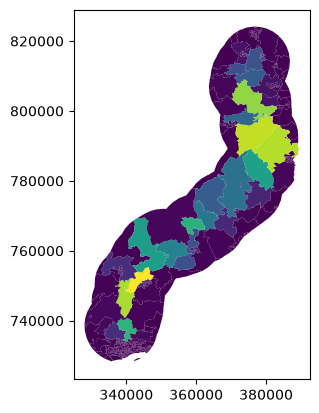

In [5]:
if "outputAreaCode" in gdf_DZ22_results.columns:
    gdf_DZ22_results = gdf_DZ22_results.set_index("outputAreaCode")
gdf_DZ22_results["empirical"] = pivot["dummy"]
gdf_DZ22_results = gdf_DZ22_results.fillna(0.0)
gdf_DZ22_results = gdf_DZ22_results.to_crs("epsg:27700")
# gdf_DZ22_results = gpd.GeoDataFrame(gdf_DZ22_results, geometry = "geometry", crs = "epsg:4326")
gdf_DZ22_results.plot(column = "cumulativeActivity")

<Axes: >

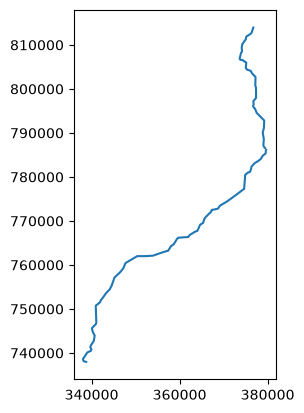

In [6]:
gdf_kt_route = gpd.read_file(r"D:\Profiles\Tim\Documents\Community Response\Codebase\data\kintore-tealing-collected-evidence\spatial\route_lines_f44d4b876709.geojson").to_crs("epsg:27700")
gdf_kt_route.plot()

In [7]:
distancesN = gdf_DZ22_results["geometry"].distance(gdf_kt_route.at[0,"geometry"])
distancesS = gdf_DZ22_results["geometry"].distance(gdf_kt_route.at[1,"geometry"])

In [21]:
distances = np.minimum(distancesN, distancesS)
gdf_DZ22_results["distance_to_route"] = distances

<Axes: >

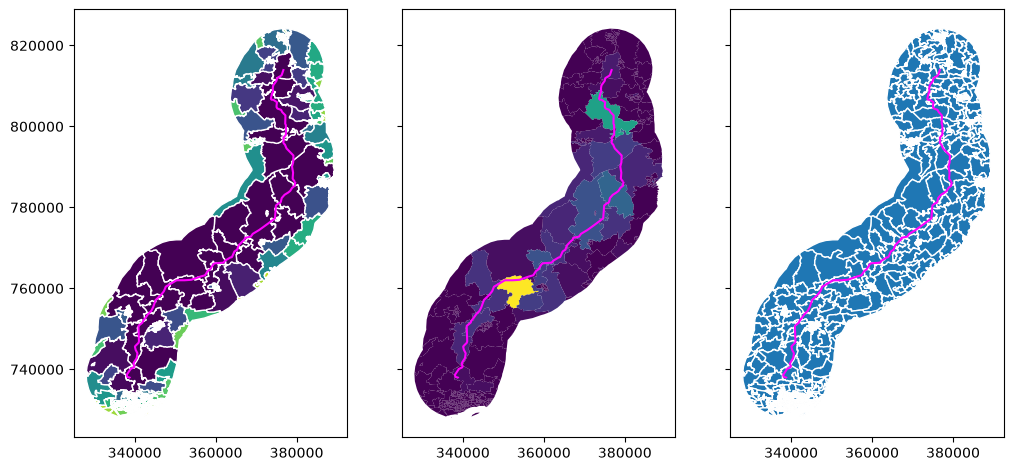

In [11]:
fig, ax = plt.subplots(ncols = 3, figsize = (12,7), sharey = True)
gdf_DZ22_results["distance_to_route"] = distances
gdf_DZ22_results.plot(column = "distance_to_route", ax = ax[0], edgecolor = "white")
gdf_kt_route.plot(ax = ax[0], edgecolor = "magenta")
gdf_kt_route.plot(ax = ax[1], edgecolor = "magenta")
gdf_kt_route.plot(ax = ax[2], edgecolor = "magenta")

gdf_DZ22_results.plot(column = "empirical", ax = ax[1])

gdf_OA_results.plot(ax = ax[2], edgecolor = "white")

# I am wondering whether there are weird gerrymandering effects here to watch out for.
# maybe the geometry needs to be projected onto the route somehow.
# E.g. if the route is near the geometry boundary, representations coming half from each side might appear less dense at first glance.

# Ad  lengh of line falling in region as a first gambit.

In [12]:
gdf_DZ22_results

,cumulativeActivity,geometry,weeklyActivity,empirical,distance_to_route
outputAreaCode,,,,,
S01013482,0.852964,"POLYGON ((384315 799988.6, 384315.001 799988.5...","[{'activity': 0.09893262580987539, 'week': 1},...",0.0,3504.062956
S01013483,0.436432,"POLYGON ((384041 801195, 384001.175 801204.19,...","[{'activity': 0.052282653221770115, 'week': 1}...",0.0,5579.078287
S01013484,0.273621,"POLYGON ((383561.069 800583.839, 383573.899 80...","[{'activity': 0.039893913485824675, 'week': 1}...",0.0,5758.693477
S01013485,0.232201,"POLYGON ((383872.071 800723.988, 383852.082 80...","[{'activity': 0.02885645009400921, 'week': 1},...",0.0,6405.758335
S01013486,0.201544,"POLYGON ((384126.04 800561.993, 384126.04 8005...","[{'activity': 0.02110430493508112, 'week': 1},...",0.0,6590.597866
...,...,...,...,...,...
S01019261,0.020390,"MULTIPOLYGON (((333052 730502, 333067.264 7305...","[{'activity': 0.004557830290920049, 'week': 1}...",0.0,8480.227004
S01019262,0.000000,"MULTIPOLYGON (((329488.502 733539.896, 329511....","[{'activity': 0.0, 'week': 1}, {'activity': 0....",0.0,8790.299414
S01019263,0.253780,"POLYGON ((335195.898 730151.796, 335209.701 73...","[{'activity': 0.029259749864827742, 'week': 1}...",0.0,8163.271403


<Axes: >

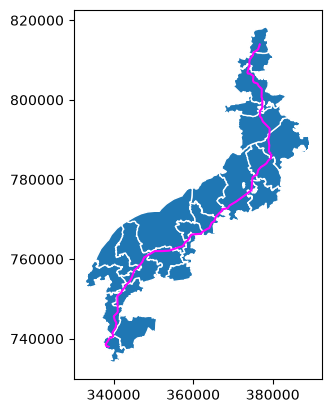

In [56]:
fig, ax = plt.subplots()
gdf_DZ22_results.loc[gdf_DZ22_results["distance_to_route"] == 0].plot(ax = ax, edgecolor = "white")
gdf_kt_route.plot(edgecolor = "magenta", ax = ax)

In [13]:
df_census_data = pd.read_csv(r"D:\Profiles\Tim\Documents\Community Response\community-response-preprocessing\data\raw\community-response-source\Census_data_aggregated_smaller\condensed_data.csv", index_col = 0)
df_census_data.head()

,p_children,mean_adult_age,p_level_4,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute
aggregation_small,,,,,,,,,,,
E01000001,0.095687,49.966468,0.832225,0.411976,0.255629,0.592141,0.727876,0.517639,0.170285,0.476262,0.020857
E01000002,0.078871,48.442655,0.835385,0.437727,0.205959,0.547619,0.759601,0.509380,0.170996,0.437220,0.021518
E01000003,0.081014,48.065276,0.700997,0.230845,0.168347,0.571695,0.619333,0.519802,0.180074,0.348697,0.026812
E01000005,0.198543,44.392045,0.403967,0.177453,0.186441,0.512704,0.294912,0.778182,0.410000,0.106383,0.064257
E01000006,0.279108,44.386792,0.349195,0.178506,0.328273,0.481040,0.230175,0.929074,0.557661,0.443648,0.254505


In [16]:
for col in df_census_data:
    gdf_DZ22_results[col] = df_census_data[col]
del df_census_data

In [23]:
gdf_DZ22_results

gdf_DZ22_results = gdf_DZ22_results.loc[:,["geometry", "cumulativeActivity", "p_children", "mean_adult_age", "p_level_4", "p_green_heating", "p_married", "p_born_in_UK", "p_L1_to_L6", "p_religion", "p_nonchristian_religion", "p_owned", "p_car_drive_commute", "distance_to_route", "empirical", ]]

gdf_DZ22_results.head()


,geometry,cumulativeActivity,p_children,mean_adult_age,p_level_4,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,distance_to_route,empirical
outputAreaCode,,,,,,,,,,,,,,,
S01013482,"POLYGON ((384315 799988.6, 384315.001 799988.5...",0.852964,0.184346,51.323232,0.426829,0.003432,0.416667,0.876939,0.402628,0.400419,0.014675,0.717119,0.509514,3504.062956,0.0
S01013483,"POLYGON ((384041 801195, 384001.175 801204.19,...",0.436432,0.169960,55.484127,0.346645,0.000000,0.456579,0.886093,0.366559,0.442408,0.036649,0.740741,0.535826,5579.078287,0.0
S01013484,"POLYGON ((383561.069 800583.839, 383573.899 80...",0.273621,0.205556,47.086247,0.428571,0.000000,0.322993,0.896296,0.410200,0.371115,0.029250,0.751381,0.593443,5758.693477,0.0
S01013485,"POLYGON ((383872.071 800723.988, 383852.082 80...",0.232201,0.229706,51.515695,0.339326,0.001976,0.410619,0.884477,0.345494,0.400362,0.052536,0.741071,0.541176,6405.758335,0.0
S01013486,"POLYGON ((384126.04 800561.993, 384126.04 8005...",0.201544,0.204800,55.655936,0.328155,0.000000,0.447504,0.909968,0.330116,0.423263,0.022617,0.676370,0.569343,6590.597866,0.0


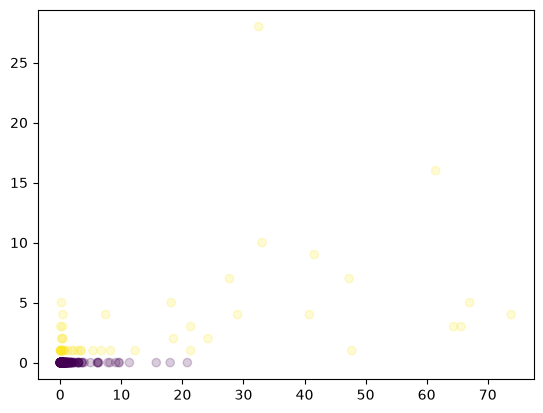

In [48]:
plt.scatter(gdf_DZ22_results["cumulativeActivity"], gdf_DZ22_results["empirical"], c = gdf_DZ22_results["empirical"].map(bool), alpha = 0.2)

# visual inspection suggests relevance of L1-L6, mean_adult_age, p_married, p_born_in_uk, p_owned, p_car_drive_commute.
# These are likely all correlated and may relate to population density or indeed to specific locations for this case study.
# p_religion seems less important which is what I'd expect.
# p_nonchristian_religion is relevant; again, is likely just a marker of urban areas, or perhaps of immigrants placing less value on British landscape.

# It is possible that these are all proxies for not living in an urbanised area??? # So we should bring back population density.

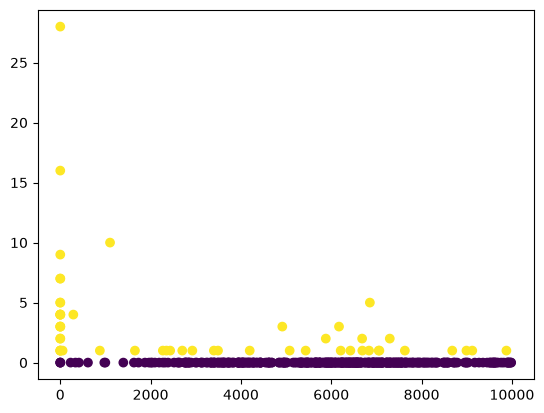

In [33]:
plt.scatter(gdf_DZ22_results["distance_to_route"], gdf_DZ22_results["empirical"], c = gdf_DZ22_results["empirical"].map(bool))

In [ ]:
# Add population density. Consider measuring the population of OPs intersected by the route.
# Consider PCA or clustering on the census data to reduce dimensions.

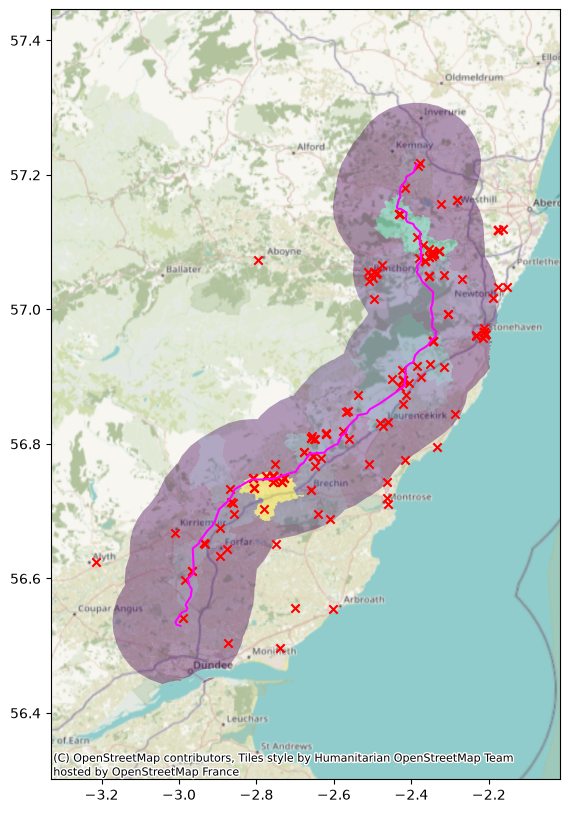

In [120]:
fig, ax = plt.subplots(figsize = (10,10))
# gdf_OA_results.to_crs("epsg:4326").plot(ax = ax, column = "cumulativeActivity", alpha = 0.4)
# gdf_OA_results.to_crs("epsg:4326").plot(ax = ax, edgecolor="magenta", linewidth=0.7)

gdf_DZ22_results.to_crs("epsg:4326").plot(ax = ax, column = "empirical", alpha = 0.4)
# gdf_DZ22_results.to_crs("epsg:4326").plot(ax = ax, column = "cumulativeActivity", alpha = 0.4)
# gdf_DZ22_results.to_crs("epsg:4326").plot(ax = ax, edgecolor = 'cyan', color = 'none', linewidth = 0.8)

gdf_kt_route.to_crs("epsg:4326").plot(color ='magenta', ax = ax)

x1,x2 = ax.get_xlim()
y1,y2 = ax.get_ylim()


gdf_likely_possible.plot(ax = ax, marker = 'x', color = 'red')

r = 1.1
ax.set_xlim(r*x1 + (1-r)*x2, r*x2 + (1-r)*x1)
ax.set_ylim(r*y1 + (1-r)*y2, r*y2 + (1-r)*y1)

cx.add_basemap(ax = ax, crs = "epsg:4326", zoom = 9)





# mean_adult_age, p_married, p_born_in_uk, p_owned, p_car_drive_commute


# Aberdeen is top right but just outside the 10km buffer.
# Big cluster at and around Drumoak.

# No responses at all from Dundee; virtually none from Aberdeen? Does this indicate that these households were not contacted personally? Can the demographics be so different as to account for it? May need to chop Dundee out of validation.

# Big clusters at Banchory, Stonehaven, and around Drumoak. Drumoak not such a big settlement, so why the difference?

# Stonehaven not showing up in data per OA. Why not?

# What is different about Brechin, Forfax, Kirriemuir versus Stonehaven, Banchory and Drumoak? Are they smaller places or just poorer? Is the route more offensive in the north?

# The complaints near Brechin mostly seem to come from Kirkton of Menmuir which is smaller.

# They are similar sized places except for Drumoak which is smaller.


# It transpires that the councils involved are Aberdeenshire, Aberdeen City, and Angus.




# Places with in-person consultation events:
# Tealing; Forfar; Memus; Brechin; Menmuir; Kintore; Echt; Drumoak; Drumlithie; Stonehaven; Laurencekirk; Durris.


# Method is pretty correct in identifying the lack of representations from Dundee.
# Somehow we've completely missed Stonehaven both from the simulated data and the aggregation of real data. Perhaps because its OA is too far outside? Or is it not actually more responsive per head and therefore doesn't show up on the chloropleth? The latter. Only a high 'per head' tally shows up in the model. Not necessarily a bad thing.





,cumulativeActivity,geometry,outputAreaCode,weeklyActivity
0,0.000000,"POLYGON ((386383 811755, 386303 811769, 386276...",S00135307,"[{'activity': 0.0, 'week': 1}, {'activity': 0...."
1,0.027038,"POLYGON ((383683.1 815966.101, 383742.101 8158...",S00135308,"[{'activity': 0.003815070604503665, 'week': 1}..."
2,0.000000,"POLYGON ((386568 812271, 386565.347 812299.302...",S00135316,"[{'activity': 0.0, 'week': 1}, {'activity': 0...."
3,0.030606,"POLYGON ((383115.402 812271.199, 383118.39 812...",S00135366,"[{'activity': 0.0010924605279001509, 'week': 1..."
4,0.018340,"POLYGON ((385653 809157, 385647 809183, 385632...",S00135400,"[{'activity': 0.0002461476984204912, 'week': 1..."


<Axes: >

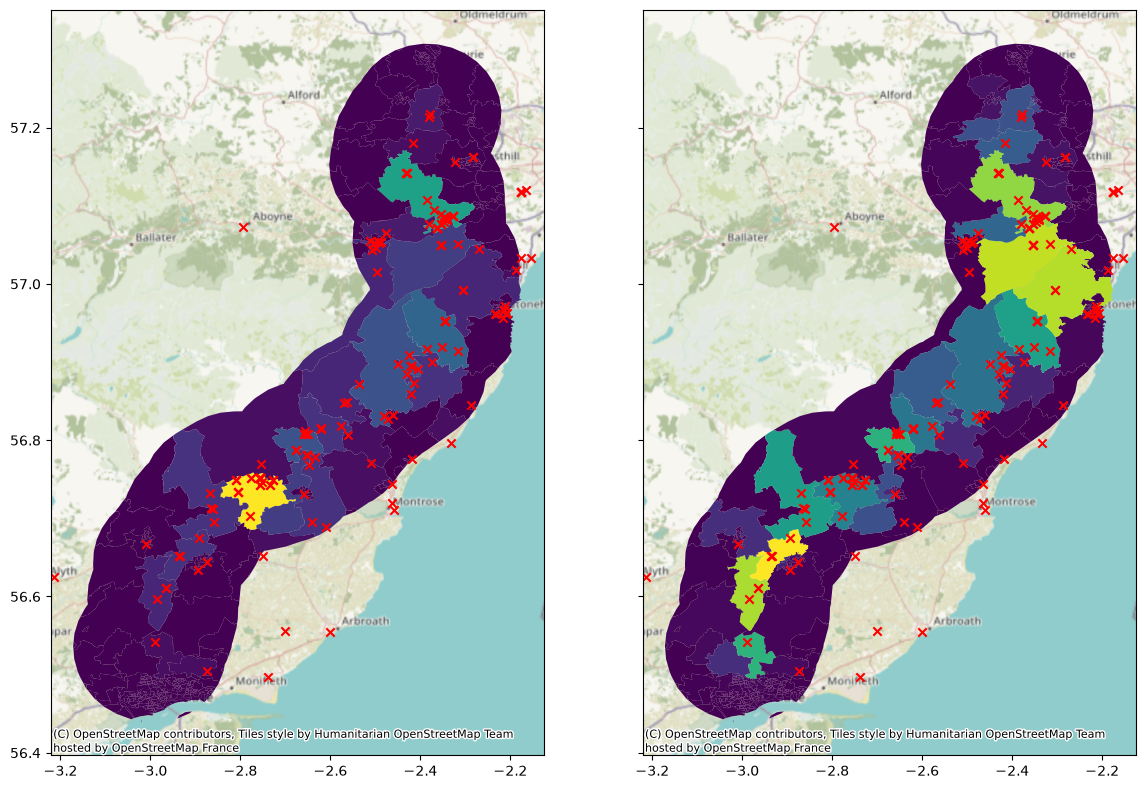

In [121]:
# Which are the Stonehaven OAs? Ah, I guess they are included, they just aren't visually prominent because it's dense.
fig, ax = plt.subplots(ncols = 2, figsize = (14,10), sharey = True)
# gdf_OA_results.to_crs("epsg:4326").plot(ax = ax, linewidth = 0, edgecolor = 'magenta', column = "cumulativeActivity")
gdf_DZ22_results.to_crs("epsg:4326").plot(ax = ax[0], linewidth = 0, edgecolor = 'magenta', column = "empirical")
gdf_DZ22_results.to_crs("epsg:4326").plot(ax = ax[1], linewidth = 0, edgecolor = 'magenta', column = "cumulativeActivity")
cx.add_basemap(ax = ax[0], crs = "epsg:4326", zoom = 9)
cx.add_basemap(ax = ax[1], crs = "epsg:4326", zoom = 9)

gdf_likely_possible.plot(ax = ax[0], marker = 'x', color = 'red')
gdf_likely_possible.plot(ax = ax[1], marker = 'x', color = 'red')

# These maps are misleading because of the visual weight given to geographic extent. The responses from dense areas are not registering visually. I suppose they are still doing a decent job of showing where responses per capita are highest.


In [ ]:
# It is probably sort of OK that we are including Dundee given that the model seems to know it won't be active. However, it might also be worth validating with Dundee excluded.

# However, if the model can't discern between communities *along* the route, I'm not sure how much value it really has.

# might be worth doing some maps with the geographies rescaled to be proportional to population??

In [136]:
gdf_DZ22_results.to_csv("Kintore-Tealing-X_Y.csv")

In [132]:
df_scotland_geog_names = pd.read_csv(r"D:\Profiles\Tim\Documents\Data for modelling\Census 2021\scoland_geography_hierarchy\data zones.csv", index_col = 0, encoding = "ISO-8859-1")
df_scotland_geog_names.head()

,DZ22_Name,IZ22_Code,IZ22_Name,MMWard_Code,MMWard_Name,LA_Code,LA_Name,SPC_Code,SPC_Name,UKPC_Code,...,UR2_Code,UR2_Name,UR3_Code,UR3_Name,UR6_Code,UR6_Name,UR8_Code,UR8_Name,Country_Code,Country_Name
DZ22_Code,,,,,,,,,,,,,,,,,,,,,
S01013482,Culter - 01,S02002515,Culter,S13002843,Lower Deeside,S12000033,Aberdeen City,S16000152,Aberdeen Deeside and North Kincardine,S14000061,...,1,Rest of Scotland,1,Rest of Scotland,1,Large Urban Areas,1,Large Urban Areas,S92000003,Scotland
S01013483,Culter - 02,S02002515,Culter,S13002843,Lower Deeside,S12000033,Aberdeen City,S16000152,Aberdeen Deeside and North Kincardine,S14000061,...,1,Rest of Scotland,1,Rest of Scotland,1,Large Urban Areas,1,Large Urban Areas,S92000003,Scotland
S01013484,Culter - 03,S02002515,Culter,S13002843,Lower Deeside,S12000033,Aberdeen City,S16000152,Aberdeen Deeside and North Kincardine,S14000061,...,1,Rest of Scotland,1,Rest of Scotland,1,Large Urban Areas,1,Large Urban Areas,S92000003,Scotland
S01013485,Culter - 04,S02002515,Culter,S13002843,Lower Deeside,S12000033,Aberdeen City,S16000152,Aberdeen Deeside and North Kincardine,S14000061,...,1,Rest of Scotland,1,Rest of Scotland,1,Large Urban Areas,1,Large Urban Areas,S92000003,Scotland
S01013486,Culter - 05,S02002515,Culter,S13002843,Lower Deeside,S12000033,Aberdeen City,S16000152,Aberdeen Deeside and North Kincardine,S14000061,...,1,Rest of Scotland,1,Rest of Scotland,1,Large Urban Areas,1,Large Urban Areas,S92000003,Scotland


In [125]:
df_scotland_urban_class = pd.read_csv(r"D:\Profiles\Tim\Documents\Data for modelling\Census 2021\Scotland 2022\OA_rural_urban_class\OA22_UR22.csv", index_col = 0)
df_scotland_urban_class.head()

,UR22_2FOLD,UR22_3FOLD,UR22_6FOLD,UR22_8FOLD
OA22,,,,
S00135307,2,2,5,6
S00135308,2,2,5,6
S00135309,2,2,5,6
S00135310,1,1,1,1
S00135311,2,2,5,6


LA_Name
Aberdeenshire        129
Angus                 78
Perth and Kinross      6
Fife                   3
Name: count, dtype: int64


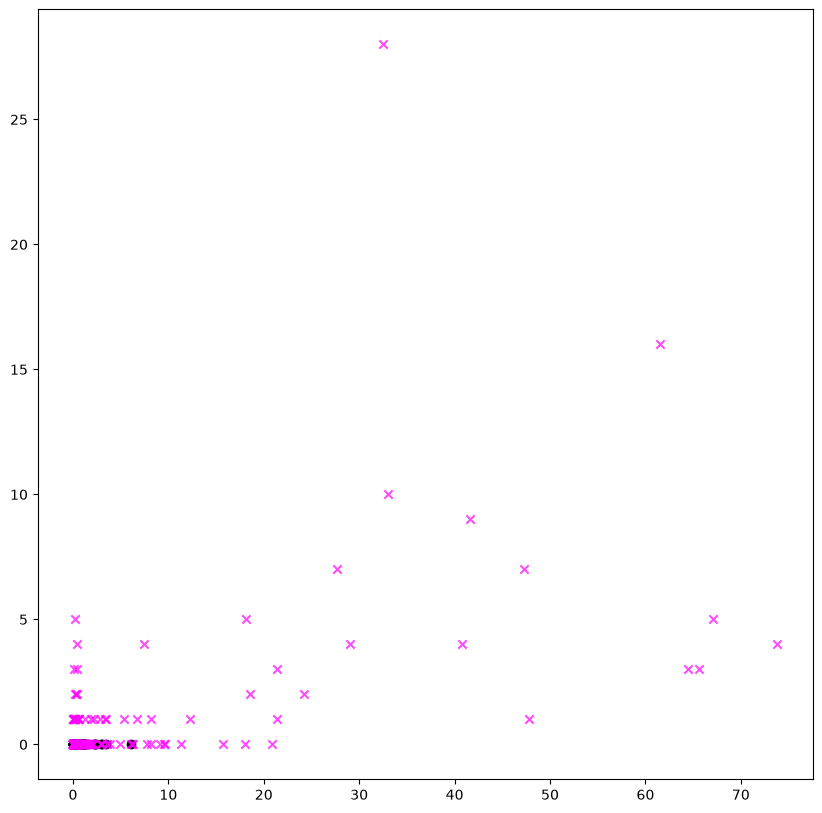

In [164]:
la_names = list(gdf_DZ22_results["LA_Name"].unique())



fig, ax = plt.subplots(figsize = (10,10))
# ax.scatter(gdf_DZ22_results["cumulativeActivity"],
#            gdf_DZ22_results["empirical"],
#            c = gdf_DZ22_results["LA_Name"].map(lambda nm:la_names.index(nm)))

df = gdf_DZ22_results.loc[gdf_DZ22_results["LA_Name"] == "Dundee City"]
ax.scatter(df["cumulativeActivity"],
           df["empirical"],
           color = "black")

df = gdf_DZ22_results.loc[gdf_DZ22_results["LA_Name"] == "Aberdeen City"]
ax.scatter(df["cumulativeActivity"],
           df["empirical"],
           color = "black")


df = gdf_DZ22_results.loc[~gdf_DZ22_results["LA_Name"].isin(["Dundee City", "Aberdeen City"])]
ax.scatter(df["cumulativeActivity"],
           df["empirical"],
           color = "magenta", alpha = 0.7, marker = 'x')

print(df["LA_Name"].value_counts())

# Model does a good job of perceiving that residents of Dundee and Aberdeen are not interested.
# Could we get rid of Dundee from this???


# Try GPR with urban rural class, density, distance, maybe one other indicator.



In [144]:
gdf_DZ22_results["LA_Name"].unique()

array(['Aberdeen City', 'Aberdeenshire', 'Angus', 'Dundee City', 'Fife',
       'Perth and Kinross'], dtype=object)

In [135]:
gdf_DZ22_results["DZ22_Name"] = df_scotland_geog_names["DZ22_Name"]
gdf_DZ22_results["IZ22_Name"] = df_scotland_geog_names["IZ22_Name"]
gdf_DZ22_results["LA_Name"] = df_scotland_geog_names["LA_Name"]

<Axes: >

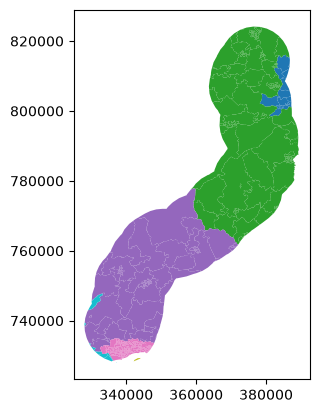

In [139]:
# gdf_DZ22_results["LA_Name"].value_counts()
gdf_DZ22_results.plot(column = "LA_Name")